# Milestone 1 — Data Profiling: Corpus-Indonesia

Sumber: [Lyon28/Corpus-Indonesia](https://huggingface.co/datasets/Lyon28/Corpus-Indonesia)

Notebook ini memeriksa file Parquet lokal, skema, jumlah baris, null/kosong, distribusi panjang teks, duplikasi, dan menyimpan laporan. File mentah tidak diubah.

Jalankan dari folder proyek `tugas1-corpus-indonesia` atau dari subfolder `notebooks`.


## Tujuan
1. Memverifikasi file sumber dan jumlah baris aktual.
2. Mengukur kualitas kolom `text`.
3. Memeriksa distribusi panjang teks dan duplikasi persis.
4. Menyimpan `output/tables/data_quality_report.json` dan `duckdb_summarize_raw.csv`.

Angka yang sebelumnya terlihat di CMD adalah 19.483.721 baris, 7 file Parquet, dan sekitar 1,9 GB. Seluruh statistik dihitung ulang saat notebook dijalankan.


In [1]:
from pathlib import Path
import json, platform
import polars as pl
import duckdb

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

CWD = Path.cwd().resolve()
ROOT = next((p for p in [CWD, *CWD.parents]
             if (p / "data/raw/corpus-indonesia/data").is_dir()), CWD)
RAW_DIR = ROOT / "data" / "raw" / "corpus-indonesia" / "data"
OUT_DIR = ROOT / "output" / "tables"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FILES = sorted(RAW_DIR.glob("*.parquet"))
if not FILES:
    raise FileNotFoundError(f"Tidak ditemukan Parquet di {RAW_DIR}. Periksa lokasi folder proyek.")

lf = pl.scan_parquet([str(p) for p in FILES])
print("Root proyek:", ROOT)
print("Polars:", pl.__version__, "| DuckDB:", duckdb.__version__)
print("Jumlah file:", len(FILES))


Root proyek: C:\Users\raihan bhakti\Desktop\tugas1-corpus-indonesia
Polars: 2.0.0 | DuckDB: 1.5.6
Jumlah file: 7


In [2]:
inventory = pl.DataFrame([
    {"file": p.name, "ukuran_bytes": p.stat().st_size,
     "ukuran_MB": round(p.stat().st_size / 1_000_000, 2)}
    for p in FILES
])
display(inventory)
total_bytes = sum(p.stat().st_size for p in FILES)
print(f"Ukuran total: {total_bytes:,} bytes")
print(f"Ukuran desimal: {total_bytes / 1e9:.3f} GB")
print("Skema:", lf.collect_schema())
total_rows = int(lf.select(pl.len().alias("n")).collect().item())
print(f"Jumlah baris aktual: {total_rows:,}")


file,ukuran_bytes,ukuran_MB
str,i64,f64
"""train-00000-of-00007.parquet""",272361891,272.36
"""train-00001-of-00007.parquet""",268977483,268.98
"""train-00002-of-00007.parquet""",271235387,271.24
"""train-00003-of-00007.parquet""",270602383,270.6
"""train-00004-of-00007.parquet""",272342018,272.34
"""train-00005-of-00007.parquet""",272175219,272.18
"""train-00006-of-00007.parquet""",272668591,272.67


Ukuran total: 1,900,362,972 bytes
Ukuran desimal: 1.900 GB
Skema: Schema([('text', String)])
Jumlah baris aktual: 19,483,721


In [3]:
text_len = pl.col("text").str.len_chars()
blank_expr = pl.col("text").is_not_null() & (pl.col("text").str.strip_chars() == "")

quality = lf.select(
    pl.len().alias("total_baris"),
    pl.col("text").null_count().alias("text_null"),
    blank_expr.sum().alias("text_kosong_atau_spasi"),
    text_len.min().alias("panjang_min_karakter"),
    text_len.max().alias("panjang_maks_karakter"),
    text_len.mean().alias("panjang_rata_rata"),
    text_len.median().alias("panjang_median"),
).collect()
display(quality)
q = quality.row(0, named=True)


total_baris,text_null,text_kosong_atau_spasi,panjang_min_karakter,panjang_maks_karakter,panjang_rata_rata,panjang_median
u32,u32,u32,u32,u32,f64,f64
19483721,0,1000001,0,180383,161.354069,87.0


kategori,jumlah
str,u32
"""00: kosong""",1000001
"""01: 1-50""",5108580
"""02: 51-100""",4389391
"""03: 101-250""",5174483
"""04: 251-500""",3045473
"""05: 501-1000""",553045
"""06: >1000""",212748


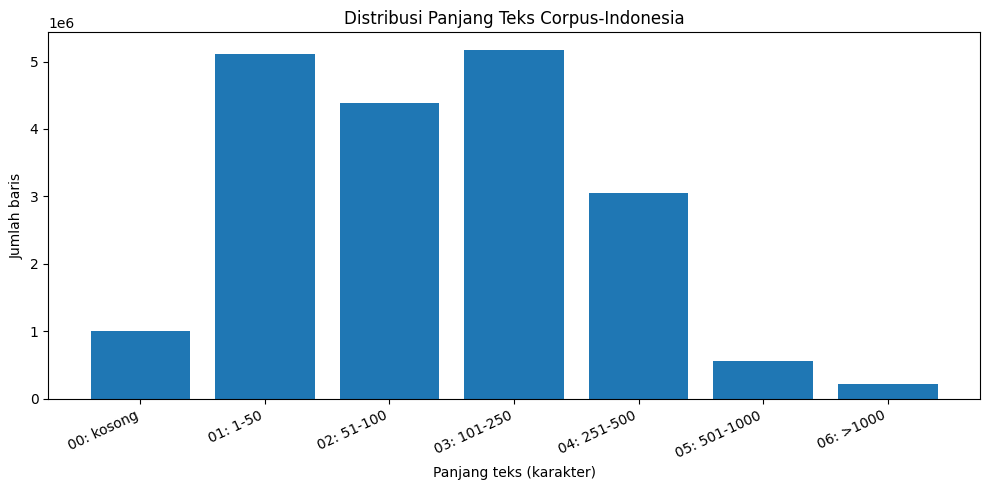

In [4]:
length = pl.col("text").str.len_chars()
category = (
    pl.when(length == 0).then(pl.lit("00: kosong"))
    .when(length <= 50).then(pl.lit("01: 1-50"))
    .when(length <= 100).then(pl.lit("02: 51-100"))
    .when(length <= 250).then(pl.lit("03: 101-250"))
    .when(length <= 500).then(pl.lit("04: 251-500"))
    .when(length <= 1000).then(pl.lit("05: 501-1000"))
    .otherwise(pl.lit("06: >1000"))
)
distribution = (
    lf.with_columns(category.alias("kategori"))
    .group_by("kategori").agg(pl.len().alias("jumlah"))
    .sort("kategori").collect()
)
display(distribution)

if plt is not None:
    plt.figure(figsize=(10, 5))
    plt.bar(distribution["kategori"].to_list(), distribution["jumlah"].to_list())
    plt.title("Distribusi Panjang Teks Corpus-Indonesia")
    plt.xlabel("Panjang teks (karakter)")
    plt.ylabel("Jumlah baris")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()


In [5]:
dup = lf.select(
    pl.len().alias("total_baris"),
    pl.col("text").n_unique().alias("jumlah_teks_unik"),
    pl.col("text").null_count().alias("text_null"),
    blank_expr.sum().alias("text_kosong_atau_spasi"),
).collect()
display(dup)
d = dup.row(0, named=True)
duplicate_excess = int(d["total_baris"] - d["jumlah_teks_unik"])
blank_count = int(d["text_kosong_atau_spasi"])
null_count = int(d["text_null"])
blank_unique = int(
    lf.filter(blank_expr).select(pl.col("text").n_unique()).collect().item()
) if blank_count else 0
blank_duplicate_excess = max(blank_count - blank_unique, 0)
null_duplicate_excess = max(null_count - 1, 0) if null_count else 0
other_duplicate_excess = duplicate_excess - blank_duplicate_excess - null_duplicate_excess

print(f"Duplikasi berlebih total: {duplicate_excess:,} ({duplicate_excess / total_rows * 100:.2f}%)")
print(f"Duplikasi berlebih dari nilai kosong: {blank_duplicate_excess:,}")
print(f"Duplikasi berlebih selain null/kosong: {other_duplicate_excess:,}")


total_baris,jumlah_teks_unik,text_null,text_kosong_atau_spasi
u32,u32,u32,u32
19483721,18483721,0,1000001


Duplikasi berlebih total: 1,000,000 (5.13%)
Duplikasi berlebih dari nilai kosong: 1,000,000
Duplikasi berlebih selain null/kosong: 0


In [6]:
print("Sampel 10 teks pertama:")
display(lf.select("text").head(10).collect())

long_samples = (
    lf.with_columns(text_len.alias("panjang_karakter"))
    .filter(pl.col("panjang_karakter") > 10_000)
    .select("panjang_karakter", pl.col("text").str.slice(0, 300).alias("cuplikan"))
    .head(10).collect()
)
print("Sampel teks lebih dari 10.000 karakter:")
display(long_samples)


Sampel 10 teks pertama:


text
str
"""Indonesia adalah negara kepula…"
"""Secara geografis, Indonesia be…"
"""Indonesia memiliki iklim tropi…"
"""Sejarah Indonesia sangat panja…"
"""Indonesia memproklamasikan kem…"
"""Peristiwa bersejarah lainnya m…"
"""Sistem pemerintahan Indonesia …"
"""Era Reformasi dimulai tahun 19…"
"""Ekonomi Indonesia terus berkem…"


Sampel teks lebih dari 10.000 karakter:


panjang_karakter,cuplikan
u32,str
25375,"""Becak Kayuh Listrik, Moda Tran…"
29059,"""Cara mendapatkan Service Pack …"
10067,"""Itulah pengertian polis asuran…"
13208,"""BrowseInterestsBiography & Mem…"
64992,"""Owned Entities (BUMD), and Nat…"
16409,"""29:1-9 = Sumbangan untuk pemba…"
16975,"""1 05 S1 Institut Sains dan Tek…"
28319,"""February 17, 2017February 18, …"
17126,"""DESY DWI FRIMADANIApril 8, 201…"


In [7]:
# Ringkasan independen menggunakan DuckDB
parquet_glob = (RAW_DIR / "*.parquet").as_posix().replace("'", "''")
con = duckdb.connect()
duck_summary = con.execute(f'''
    SELECT COUNT(*) AS total_baris,
           COUNT(*) FILTER (WHERE text IS NULL) AS text_null,
           COUNT(*) FILTER (WHERE text IS NOT NULL AND length(trim(text)) = 0) AS text_kosong_atau_spasi,
           MIN(length(text)) AS panjang_min_karakter,
           MAX(length(text)) AS panjang_maks_karakter,
           AVG(length(text)) AS panjang_rata_rata
    FROM read_parquet('{parquet_glob}')
''').df()
display(duck_summary)
duck_csv = OUT_DIR / "duckdb_summarize_raw.csv"
duck_summary.to_csv(duck_csv, index=False)
con.close()
print("CSV DuckDB:", duck_csv)


,total_baris,text_null,text_kosong_atau_spasi,panjang_min_karakter,panjang_maks_karakter,panjang_rata_rata
0,19483721,0,1000001,0,180383,161.354069


CSV DuckDB: C:\Users\raihan bhakti\Desktop\tugas1-corpus-indonesia\output\tables\duckdb_summarize_raw.csv


In [8]:
def safe(v):
    return v.item() if hasattr(v, "item") else v

report = {
    "dataset": "Corpus-Indonesia",
    "source_url": "https://huggingface.co/datasets/Lyon28/Corpus-Indonesia",
    "source_license_as_documented": "Apache-2.0 (sesuai metadata yang terlihat; verifikasi ketentuan sumber sebelum redistribusi)",
    "source_directory": "data/raw/corpus-indonesia/data/",
    "source_file_count": len(FILES),
    "source_size_bytes": total_bytes,
    "polars_version": pl.__version__,
    "duckdb_version": duckdb.__version__,
    "schema": {k: str(v) for k, v in lf.collect_schema().items()},
    "before_cleaning": {k: safe(v) for k, v in q.items()},
    "length_distribution": distribution.to_dicts(),
    "duplicate_analysis": {
        "total_rows": int(d["total_baris"]),
        "unique_text_values": int(d["jumlah_teks_unik"]),
        "duplicate_excess": duplicate_excess,
        "blank_rows": blank_count,
        "unique_blank_values": blank_unique,
        "blank_duplicate_excess": blank_duplicate_excess,
        "null_rows": null_count,
        "other_duplicate_excess": other_duplicate_excess,
        "duplicate_excess_percentage": round(duplicate_excess / total_rows * 100, 4),
    },
    "notes": [
        "Teks panjang tidak otomatis dianggap rusak.",
        "Teks kosong perlu ditangani pada Milestone 2.",
        "Aturan deduplikasi mengikuti hasil pemeriksaan duplikasi non-kosong.",
    ],
    "duckdb_summarize_file": "output/tables/duckdb_summarize_raw.csv",
}
report_path = OUT_DIR / "data_quality_report.json"
with report_path.open("w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2, default=str)
print("Laporan disimpan:", report_path)


Laporan disimpan: C:\Users\raihan bhakti\Desktop\tugas1-corpus-indonesia\output\tables\data_quality_report.json


## Kesimpulan Milestone 1

Gunakan tabel dan laporan hasil eksekusi untuk menjelaskan jumlah baris, nilai null/kosong, distribusi panjang teks, serta duplikasi. Jangan menghapus teks panjang hanya berdasarkan panjangnya. Setelah laporan tersimpan, lanjutkan ke `02_data_cleaning.ipynb`.
